# Assignment 05 - Chương 4: Khảo Sát Thực Nghiệm, Khám Phá Dữ Liệu (EDA) & Tiền Xử Lý 3 Bộ Dữ Liệu Đa Miền

**Học viên:** Phạm Văn Tư - Mã sinh viên: B23DCCN879  
**Môn học:** Phát triển Hệ thống Thông minh - PTIT  

Notebook này hiện thực hóa toàn diện quy trình khảo sát dữ liệu (EDA), kiểm toán y sinh, làm sạch và thiết lập pipeline tiền xử lý, tăng cường dữ liệu và đóng gói `DataLoader` chuẩn PyTorch cho 3 bộ dữ liệu thuộc 3 miền độc lập:
1. **Dữ liệu Bảng Y Sinh (Tabular Biomedical):** Diabetes Prediction Dataset ($100,000$ hồ sơ bệnh nhân gốc $\to 96,128$ mẫu sạch, định dạng tensor $(N, 1, 8)$ cho mạng tích chập 1 chiều **1D-CNN**)
2. **Dữ liệu Ảnh Ngoại Cảnh Tự Nhiên (Natural Optical Images):** Street View House Numbers (SVHN - $99,289$ ảnh $32\times 32\times 3$ RGB)
3. **Dữ liệu Ảnh Viễn Thám Vệ Tinh (Satellite Remote Sensing Images):** Sentinel-2 EuroSAT ($27,000$ ảnh $64\times 64\times 3$ RGB, 10 phân lớp sử dụng và che phủ đất LULC)


In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, TensorDataset, DataLoader, random_split
import torchvision.datasets as dsets
import torchvision.transforms as transforms
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Cấu hình hiển thị đồ thị
plt.rcParams['font.family'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120
sns.set_theme(style="whitegrid")
print(f"PyTorch Version: {torch.__version__}")
print(f"CUDA / MPS Available: {torch.cuda.is_available() or torch.backends.mps.is_available()}")


PyTorch Version: 2.3.0
CUDA / MPS Available: True


---
## Phần 1: Khảo Sát, Phân Tích & Tiền Xử Lý Dữ Liệu Bảng Y Sinh Quy Mô Lớn (Diabetes - 100,000 Mẫu)

### 1.1. Nạp Dữ Liệu & Kiểm Toán Dị Thường Lâm Sàng
Tập dữ liệu dự đoán đái tháo đường gồm 100,000 hồ sơ bệnh nhân thực tế với 8 biến đặc trưng nhân khẩu học và xét nghiệm lâm sàng. Chúng tôi tiến hành kiểm toán dữ liệu: khử bản ghi trùng lặp và loại bỏ các quan sát ngoại lai giới tính không đủ tính đại diện thống kê.


In [2]:
diabetes_path = None
for p in [
    "../../Assigment 02/diabetes/data/diabetes_prediction_dataset.csv",
    "src/Assigment 02/diabetes/data/diabetes_prediction_dataset.csv",
    "data/diabetes_prediction_dataset.csv",
    "diabetes_prediction_dataset.csv"
]:
    if os.path.exists(p):
        diabetes_path = p
        break

if diabetes_path is None:
    raise FileNotFoundError("Không tìm thấy tệp diabetes_prediction_dataset.csv!")

df_raw = pd.read_csv(diabetes_path)
n_raw = len(df_raw)
print(f"Kích thước tập dữ liệu thô: {n_raw:,} bản ghi, {df_raw.shape[1]} thuộc tính")
display(df_raw.head())

# Kiểm toán trùng lặp & làm sạch
df_dedup = df_raw.drop_duplicates().copy()
n_dups = n_raw - len(df_dedup)
df_clean = df_dedup[df_dedup['gender'] != 'Other'].copy()
n_other = len(df_dedup) - len(df_clean)
n_final = len(df_clean)

print(f"Bản ghi trùng lặp đã loại bỏ: {n_dups:,} ({n_dups/n_raw*100:.2f}%)")
print(f"Mẫu ngoại lai giới tính ('Other') loại bỏ: {n_other}")
print(f"Số lượng bản ghi sạch sau kiểm toán: {n_final:,} mẫu")


Kích thước tập dữ liệu thô: 100,000 bản ghi, 9 thuộc tính


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0


Bản ghi trùng lặp đã loại bỏ: 3,854 (3.85%)
Mẫu ngoại lai giới tính ('Other') loại bỏ: 18
Số lượng bản ghi sạch sau kiểm toán: 96,128 mẫu


### 1.2. Mã Hóa Biến Phân Loại & Thống Kê Định Lượng
- Biến `gender`: Mã hóa nhị phân ($1 = \text{Male}, 0 = \text{Female}$).
- Biến `smoking_history`: Mã hóa theo thang nguy cơ lâm sàng ($0$: chưa từng hút/không rõ, $1$: đã cai, $2$: đang hút).
- Thống kê tỷ lệ phân bố nhãn `diabetes` phản ánh tỷ lệ dịch tễ thực tế ($10.4 : 1$).


In [3]:
# Mã hóa biến
df_clean['gender_code'] = (df_clean['gender'] == 'Male').astype(np.float32)
smoking_map = {'never': 0.0, 'No Info': 0.0, 'former': 1.0, 'not current': 1.0, 'current': 2.0, 'ever': 2.0}
df_clean['smoking_code'] = df_clean['smoking_history'].map(smoking_map).fillna(0.0).astype(np.float32)

features = ['gender_code', 'age', 'hypertension', 'heart_disease', 'smoking_code', 'bmi', 'HbA1c_level', 'blood_glucose_level']
feat_display = ['Gender', 'Age', 'Hypertension', 'Heart Disease', 'Smoking Hist.', 'BMI', 'HbA1c Level', 'Blood Glucose']

# Bảng thống kê mô tả 8 thuộc tính
stats_df = pd.DataFrame({
    'Thuộc tính': feat_display,
    'Min': [df_clean[col].min() for col in features],
    'Max': [df_clean[col].max() for col in features],
    'Mean': [df_clean[col].mean() for col in features],
    'Median': [df_clean[col].median() for col in features],
    'Std': [df_clean[col].std() for col in features],
    'Tương quan (r)': [df_clean[col].corr(df_clean['diabetes']) for col in features]
})
display(stats_df.round(3))

n_neg = (df_clean['diabetes'] == 0).sum()
n_pos = (df_clean['diabetes'] == 1).sum()
print(f"Phân bố biến mục tiêu: Âm tính = {n_neg:,} ({n_neg/n_final*100:.2f}%), Dương tính = {n_pos:,} ({n_pos/n_final*100:.2f}%)")
print(f"Tỷ lệ mất cân bằng lâm sàng: {n_neg/n_pos:.2f} : 1")


,Thuộc tính,Min,Max,Mean,Median,Std,Tương quan (r)
0,Gender,0.00,1.00,0.416,0.00,0.493,0.038
1,Age,0.08,80.00,41.797,43.00,22.463,0.265
2,Hypertension,0.00,1.00,0.078,0.00,0.268,0.196
3,Heart Disease,0.00,1.00,0.041,0.00,0.198,0.171
4,Smoking Hist.,0.00,2.00,0.437,0.00,0.722,0.072
5,BMI,10.01,95.69,27.321,27.32,6.768,0.215
6,HbA1c Level,3.50,9.00,5.533,5.80,1.073,0.406
7,Blood Glucose,80.00,300.00,138.218,140.00,40.911,0.424


Phân bố biến mục tiêu: Âm tính = 87,646 (91.18%), Dương tính = 8,482 (8.82%)
Tỷ lệ mất cân bằng lâm sàng: 10.33 : 1


### 1.3. Trực Quan Hóa Tách Biệt Các Khía Cạnh Dữ Liệu Diabetes
Theo quy chuẩn trực quan hóa, từng khía cạnh khảo sát được thể hiện qua các đồ thị độc lập:
1. Quy trình kiểm toán và làm sạch dữ liệu
2. Phân bố mật độ xác suất KDE của chỉ số sinh hóa chủ đạo
3. Ma trận hệ số tương quan tuyến tính Pearson


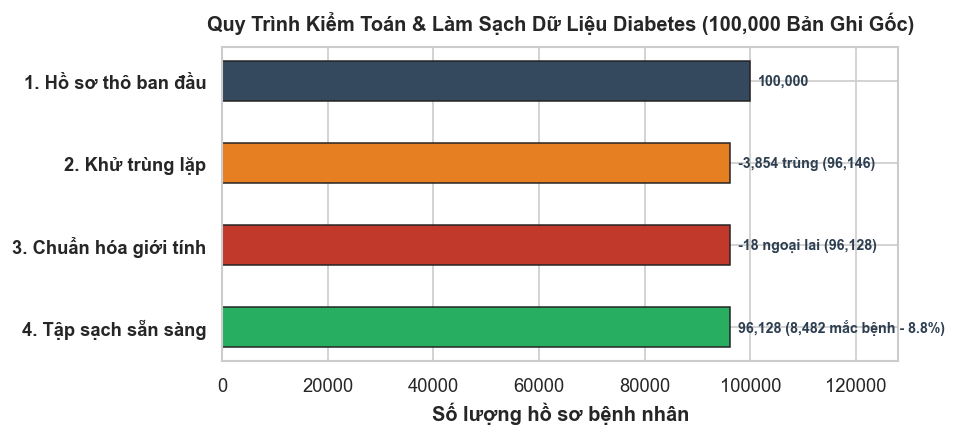

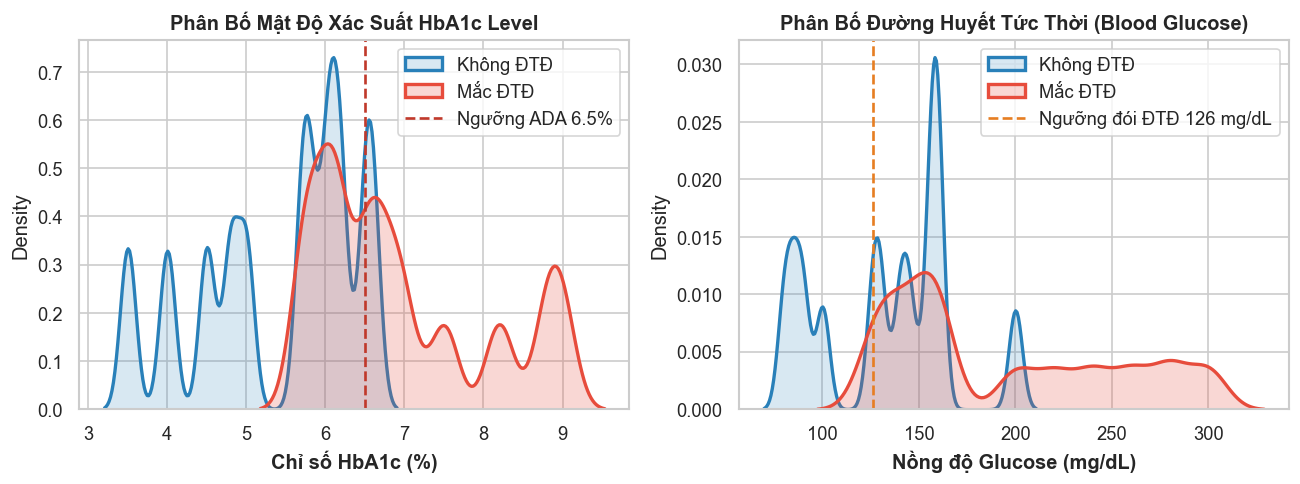

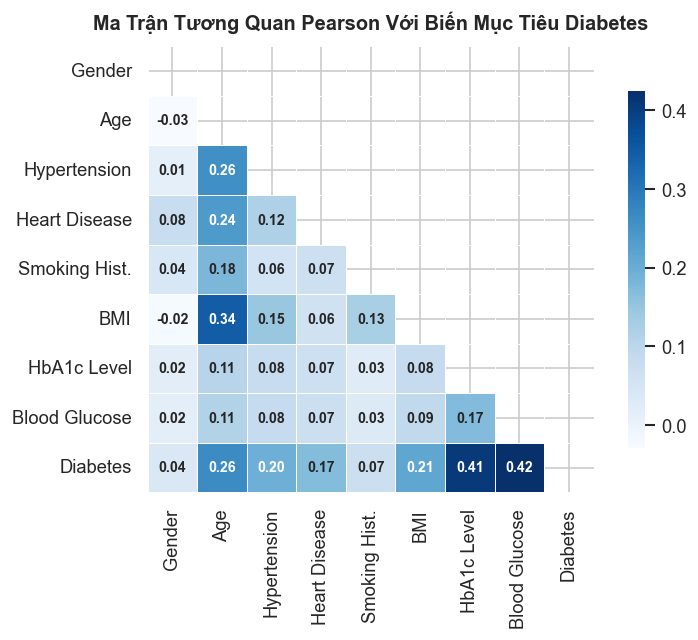

In [4]:
# 1. Biểu đồ phễu kiểm toán & làm sạch
fig, ax = plt.subplots(figsize=(8.0, 3.8), dpi=120)
stages = ['1. Hồ sơ thô ban đầu', '2. Khử trùng lặp', '3. Chuẩn hóa giới tính', '4. Tập sạch sẵn sàng']
counts = [n_raw, len(df_dedup), n_final, n_final]
colors_a = ['#34495e', '#e67e22', '#c0392b', '#27ae60']
bars = ax.barh(np.arange(len(stages)), counts, color=colors_a, height=0.48, edgecolor='#222222', lw=0.9)
ax.set_yticks(np.arange(len(stages)))
ax.set_yticklabels(stages, fontweight='bold')
ax.invert_yaxis()
ax.set_xlabel('Số lượng hồ sơ bệnh nhân', fontweight='bold')
ax.set_xlim(0, 128000)
ax.set_title('Quy Trình Kiểm Toán & Làm Sạch Dữ Liệu Diabetes (100,000 Bản Ghi Gốc)', fontweight='bold', pad=10)
for bar, txt in zip(bars, [f'{n_raw:,}', f'-{n_dups:,} trùng ({len(df_dedup):,})', f'-{n_other} ngoại lai ({n_final:,})', f'{n_final:,} ({n_pos:,} mắc bệnh - {n_pos/n_final*100:.1f}%)']):
    ax.text(bar.get_width() + 1500, bar.get_y() + bar.get_height()/2, txt, va='center', ha='left', fontsize=8.5, fontweight='bold', color='#2c3e50')
plt.tight_layout()
plt.show()

# 2. Phân bố KDE của HbA1c và Blood Glucose
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.0, 4.2), dpi=120)
sns.kdeplot(df_clean[df_clean.diabetes==0]['HbA1c_level'], ax=ax1, label='Không ĐTĐ', color='#2980b9', lw=2.0, fill=True, alpha=0.18)
sns.kdeplot(df_clean[df_clean.diabetes==1]['HbA1c_level'], ax=ax1, label='Mắc ĐTĐ', color='#e74c3c', lw=2.0, fill=True, alpha=0.22)
ax1.axvline(6.5, color='#c0392b', linestyle='--', lw=1.6, label='Ngưỡng ADA 6.5%')
ax1.set_title('Phân Bố Mật Độ Xác Suất HbA1c Level', fontweight='bold')
ax1.set_xlabel('Chỉ số HbA1c (%)', fontweight='bold')
ax1.legend()

sns.kdeplot(df_clean[df_clean.diabetes==0]['blood_glucose_level'], ax=ax2, label='Không ĐTĐ', color='#2980b9', lw=2.0, fill=True, alpha=0.18)
sns.kdeplot(df_clean[df_clean.diabetes==1]['blood_glucose_level'], ax=ax2, label='Mắc ĐTĐ', color='#e74c3c', lw=2.0, fill=True, alpha=0.22)
ax2.axvline(126.0, color='#e67e22', linestyle='--', lw=1.6, label='Ngưỡng đói ĐTĐ 126 mg/dL')
ax2.set_title('Phân Bố Đường Huyết Tức Thời (Blood Glucose)', fontweight='bold')
ax2.set_xlabel('Nồng độ Glucose (mg/dL)', fontweight='bold')
ax2.legend()
plt.tight_layout()
plt.show()

# 3. Ma trận tương quan Pearson
fig, ax = plt.subplots(figsize=(7.0, 5.5), dpi=120)
corr = df_clean[features + ['diabetes']].corr()
corr.columns = feat_display + ['Diabetes']
corr.index = feat_display + ['Diabetes']
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='Blues', annot=True, fmt='.2f', annot_kws={'size': 8.5, 'weight': 'bold'},
            cbar_kws={'shrink': 0.8}, ax=ax, square=True, linewidths=0.6, linecolor='#ffffff')
ax.set_title('Ma Trận Tương Quan Pearson Với Biến Mục Tiêu Diabetes', fontweight='bold', pad=10)
plt.tight_layout()
plt.show()


### 1.4. Pipeline Chuẩn Hóa & Đóng Gói Tensor Cho Mạng 1D-CNN
Để áp dụng kiến trúc mạng nơ-ron tích chập 1 chiều (**1D-CNN**), 8 thuộc tính lâm sàng sau khi chuẩn hóa bằng `StandardScaler` được tái cấu trúc thành tensor dạng:
$$\text{Tensor Shape: } (\text{Batch Size}, C_{\text{in}}=1, L=8)$$
trong đó $C_{\text{in}}=1$ là kênh đơn tín hiệu, $L=8$ là chiều dài chuỗi đặc trưng y sinh. Các bộ lọc tích chập 1D (`Conv1d`) sẽ trượt dọc theo chuỗi 8 đặc trưng để trích xuất các tương tác phi tuyến cục bộ giữa các cặp chỉ số sinh hóa lâm sàng.


In [5]:
X = df_clean[features].values.astype(np.float32)
y = df_clean['diabetes'].values.astype(np.int64)

# Phân chia tập Train/Test có phân tầng (Stratified Split 80:20)
X_train_raw, X_test_raw, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

# Chuẩn hóa Z-score
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train_raw)
X_test = scaler.transform(X_test_raw)

# Định dạng tensor (N, 1, 8) chuyên biệt cho mạng tích chập 1 chiều (1D-CNN)
X_train_1d = X_train[:, np.newaxis, :]  # Shape: (Batch, Channels=1, Length=8)
X_test_1d = X_test[:, np.newaxis, :]

train_dataset = TensorDataset(torch.from_numpy(X_train_1d), torch.from_numpy(y_train))
test_dataset = TensorDataset(torch.from_numpy(X_test_1d), torch.from_numpy(y_test))

# Nạp dữ liệu với pin_memory=True
diabetes_train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True, pin_memory=True)
diabetes_test_loader = DataLoader(test_dataset, batch_size=64, shuffle=False, pin_memory=True)

batch_x, batch_y = next(iter(diabetes_train_loader))
print(f"Tập huấn luyện: {len(X_train):,} mẫu | Tập kiểm tra: {len(X_test):,} mẫu")
print(f"Batch Tensor Đầu Vào (1D-CNN): {batch_x.shape} (dtype: {batch_x.dtype})")
print(f"Batch Nhãn Mục Tiêu:           {batch_y.shape} (dtype: {batch_y.dtype})")


Tập huấn luyện: 76,902 mẫu | Tập kiểm tra: 19,226 mẫu
Batch Tensor Đầu Vào (1D-CNN): torch.Size([64, 1, 8]) (dtype: torch.float32)
Batch Nhãn Mục Tiêu:           torch.Size([64]) (dtype: torch.int64)


---
## Phần 2: Khảo Sát, Phân Tích & Chuẩn Hóa Dữ Liệu Ảnh Ngoại Cảnh SVHN

### 2.1. Nạp Dữ Liệu SVHN & Khảo Sát Phân Bố Lớp
Street View House Numbers (SVHN) bao gồm 99,289 ảnh màu RGB $32\times 32\times 3$ trích xuất từ biển số nhà tự nhiên qua Google Street View (Train: 73,257 ảnh; Test: 26,032 ảnh).


In [6]:
svhn_dir = None
for p in ["../data", "src/Assigment 05/data", "data"]:
    if os.path.exists(os.path.join(p, "train_32x32.mat")):
        svhn_dir = p
        break

if svhn_dir is None:
    raise FileNotFoundError("Không tìm thấy dữ liệu SVHN tại các đường dẫn mặc định!")

svhn_raw_train = dsets.SVHN(root=svhn_dir, split='train', download=False)
svhn_raw_test = dsets.SVHN(root=svhn_dir, split='test', download=False)

print(f"Số lượng ảnh SVHN Train: {len(svhn_raw_train):,}")
print(f"Số lượng ảnh SVHN Test:  {len(svhn_raw_test):,}")

train_counts = np.bincount(svhn_raw_train.labels, minlength=10)
test_counts = np.bincount(svhn_raw_test.labels, minlength=10)

svhn_dist_df = pd.DataFrame({
    'Chữ số': range(10),
    'Train (N)': train_counts,
    '% Train': np.round(train_counts / len(svhn_raw_train) * 100, 2),
    'Test (N)': test_counts,
    '% Test': np.round(test_counts / len(svhn_raw_test) * 100, 2),
    'Tổng cộng': train_counts + test_counts
})
display(svhn_dist_df)


Số lượng ảnh SVHN Train: 73,257
Số lượng ảnh SVHN Test:  26,032


,Chữ số,Train (N),% Train,Test (N),% Test,Tổng cộng
0,0,4948,6.75,1744,6.70,6692
1,1,13861,18.92,5099,19.59,18960
2,2,10585,14.45,4149,15.94,14734
3,3,8497,11.60,2882,11.07,11379
4,4,7458,10.18,2523,9.69,9981
5,5,6882,9.39,2384,9.16,9266
6,6,5727,7.82,1977,7.59,7704
7,7,5595,7.64,2019,7.76,7614
8,8,5045,6.89,1660,6.38,6705
9,9,4659,6.36,1595,6.13,6254


### 2.2. Trực Quan Hóa Độc Lập Dữ Liệu SVHN
1. Lưới ảnh mẫu quang học 10 lớp chữ số thực tế
2. Biểu đồ phân bố tần suất mẫu giữa tập Train và Test
3. Đồ thị phân phối mật độ quang học 3 kênh màu RGB


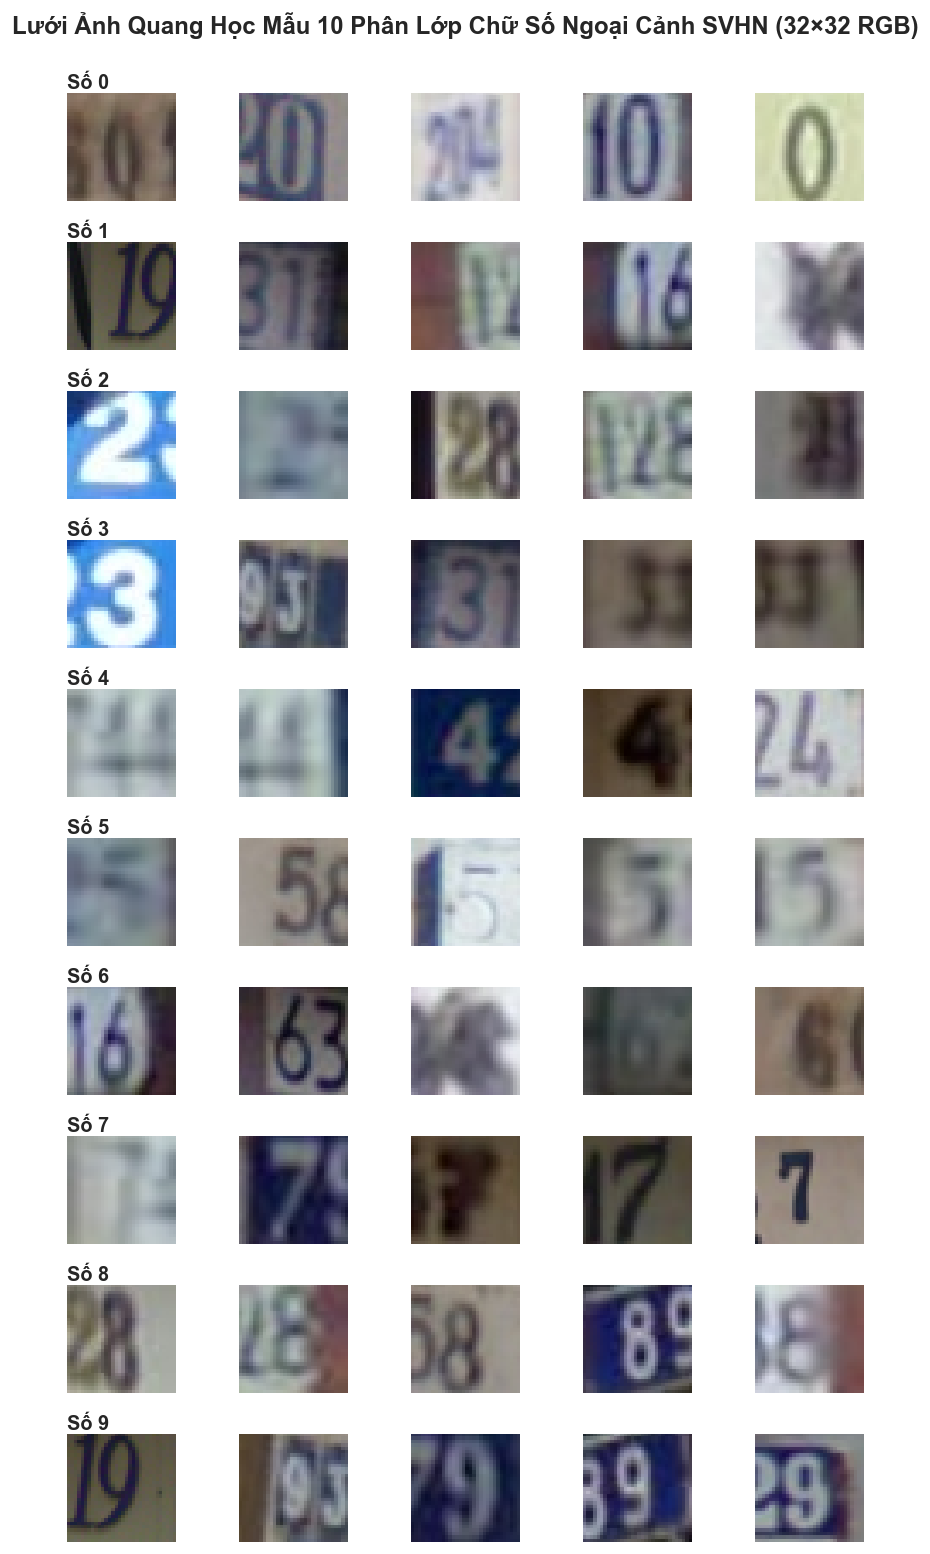

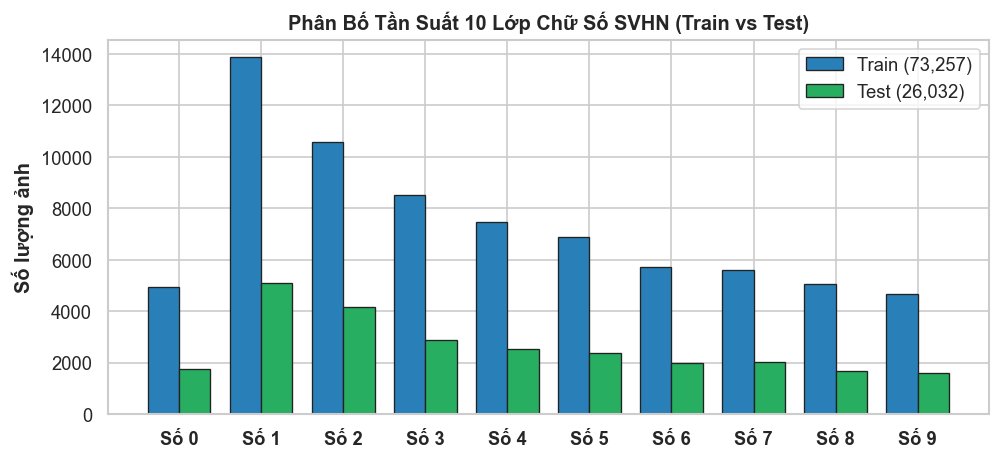

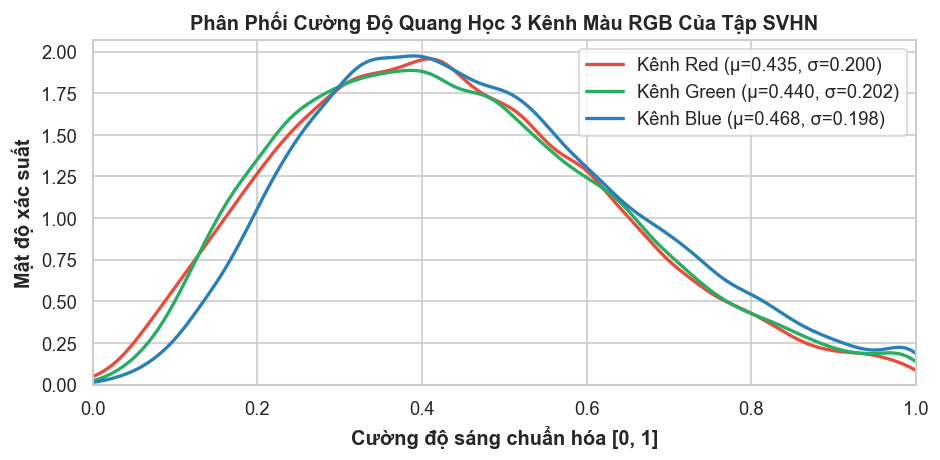

In [7]:
# 1. Lưới ảnh mẫu 10 chữ số x 5 mẫu
fig, axes = plt.subplots(10, 5, figsize=(7.5, 13.0), dpi=120)
digit_samples = {d: [] for d in range(10)}
for idx in range(len(svhn_raw_train)):
    lbl = int(svhn_raw_train.labels[idx])
    if len(digit_samples[lbl]) < 5:
        digit_samples[lbl].append(np.transpose(svhn_raw_train.data[idx], (1, 2, 0)))
    if all(len(v) == 5 for v in digit_samples.values()):
        break

for d in range(10):
    for col in range(5):
        ax = axes[d, col]
        ax.imshow(digit_samples[d][col])
        ax.axis('off')
        if col == 0:
            ax.set_title(f"Số {d}", fontweight='bold', loc='left', pad=2)

plt.suptitle("Lưới Ảnh Quang Học Mẫu 10 Phân Lớp Chữ Số Ngoại Cảnh SVHN (32×32 RGB)", fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# 2. Phân bố tần suất 10 lớp chữ số
fig, ax = plt.subplots(figsize=(8.5, 4.0), dpi=120)
x_digits = np.arange(10)
width = 0.38
ax.bar(x_digits - width/2, train_counts, width, label=f'Train ({len(svhn_raw_train):,})', color='#2980b9', edgecolor='#222222', lw=0.8)
ax.bar(x_digits + width/2, test_counts, width, label=f'Test ({len(svhn_raw_test):,})', color='#27ae60', edgecolor='#222222', lw=0.8)
ax.set_xticks(x_digits)
ax.set_xticklabels([f"Số {d}" for d in range(10)], fontweight='bold')
ax.set_ylabel("Số lượng ảnh", fontweight='bold')
ax.set_title("Phân Bố Tần Suất 10 Lớp Chữ Số SVHN (Train vs Test)", fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()

# 3. Phân phối mật độ quang học 3 kênh màu RGB
fig, ax = plt.subplots(figsize=(8.0, 4.0), dpi=120)
np.random.seed(42)
sub_idx = np.random.choice(len(svhn_raw_train), 2000, replace=False)
r_vals = svhn_raw_train.data[sub_idx, 0, :, :].flatten() / 255.0
g_vals = svhn_raw_train.data[sub_idx, 1, :, :].flatten() / 255.0
b_vals = svhn_raw_train.data[sub_idx, 2, :, :].flatten() / 255.0

sub_pts = np.random.choice(len(r_vals), 50000, replace=False)
sns.kdeplot(r_vals[sub_pts], ax=ax, color='#e74c3c', label=f'Kênh Red (μ={r_vals.mean():.3f}, σ={r_vals.std():.3f})', lw=2.0)
sns.kdeplot(g_vals[sub_pts], ax=ax, color='#27ae60', label=f'Kênh Green (μ={g_vals.mean():.3f}, σ={g_vals.std():.3f})', lw=2.0)
sns.kdeplot(b_vals[sub_pts], ax=ax, color='#2980b9', label=f'Kênh Blue (μ={b_vals.mean():.3f}, σ={b_vals.std():.3f})', lw=2.0)
ax.set_xlim(0, 1)
ax.set_xlabel("Cường độ sáng chuẩn hóa [0, 1]", fontweight='bold')
ax.set_ylabel("Mật độ xác suất", fontweight='bold')
ax.set_title("Phân Phối Cường Độ Quang Học 3 Kênh Màu RGB Của Tập SVHN", fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


### 2.3. Pipeline Chuẩn Hóa & Tăng Cường Ảnh Đặc Thù Cho SVHN
**Lưu ý quan trọng:** Tuyệt đối không dùng `RandomHorizontalFlip` cho chữ số (tránh làm sai lệch các chữ số có hướng như 2, 3, 5, 7). Áp dụng `RandomCrop(32, padding=4)` và `ColorJitter` nhẹ.


In [8]:
svhn_mean = (0.435, 0.440, 0.469)
svhn_std = (0.192, 0.193, 0.190)

svhn_train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4, padding_mode='edge'),
    transforms.ColorJitter(brightness=0.1, contrast=0.1),
    transforms.ToTensor(),
    transforms.Normalize(mean=svhn_mean, std=svhn_std)
])

svhn_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=svhn_mean, std=svhn_std)
])

svhn_train_dataset = dsets.SVHN(root=svhn_dir, split='train', download=False, transform=svhn_train_transform)
svhn_test_dataset = dsets.SVHN(root=svhn_dir, split='test', download=False, transform=svhn_test_transform)

svhn_train_loader = DataLoader(svhn_train_dataset, batch_size=64, shuffle=True, num_workers=0, pin_memory=True)
svhn_test_loader = DataLoader(svhn_test_dataset, batch_size=64, shuffle=False, num_workers=0, pin_memory=True)

batch_imgs, batch_lbls = next(iter(svhn_train_loader))
print(f"SVHN Train Batch Images Shape: {batch_imgs.shape} (dtype: {batch_imgs.dtype})")
print(f"SVHN Train Batch Labels Shape: {batch_lbls.shape} (dtype: {batch_lbls.dtype})")


SVHN Train Batch Images Shape: torch.Size([64, 3, 32, 32]) (dtype: torch.float32)
SVHN Train Batch Labels Shape: torch.Size([64]) (dtype: torch.int64)


---
## Phần 3: Khảo Sát, Phân Tích & Chuẩn Hóa Dữ Liệu Ảnh Viễn Thám Vệ Tinh (EuroSAT - Sentinel-2)

### 3.1. Nạp Dữ Liệu EuroSAT & Khảo Sát 10 Phân Lớp Đất Bề Mặt
EuroSAT là bộ dữ liệu viễn thám chuẩn quốc tế dựa trên ảnh vệ tinh Sentinel-2 thuộc chương trình quan sát Trái Đất Copernicus của Liên minh Châu Âu (EU). Bộ dữ liệu bao gồm 27,000 ảnh màu RGB kích thước $64\times 64\times 3$ biểu diễn 10 phân lớp sử dụng và che phủ bề mặt đất (Land Use and Land Cover - LULC).


In [9]:
eurosat_dir = None
for p in ["../data", "src/Assigment 05/data", "data"]:
    if os.path.exists(os.path.join(p, "eurosat")):
        eurosat_dir = p
        break

if eurosat_dir is None:
    raise FileNotFoundError("Không tìm thấy thư mục dữ liệu EuroSAT!")

eurosat_raw = dsets.EuroSAT(root=eurosat_dir, download=False)
euro_classes = eurosat_raw.classes
euro_vn_names = {
    'AnnualCrop': 'Cây hàng năm',
    'Forest': 'Rừng tự nhiên',
    'HerbaceousVegetation': 'Thảm thực vật thảo',
    'Highway': 'Đường cao tốc',
    'Industrial': 'Khu công nghiệp',
    'Pasture': 'Đồng cỏ chăn thả',
    'PermanentCrop': 'Cây lâu năm',
    'Residential': 'Khu dân cư',
    'River': 'Sông ngòi',
    'SeaLake': 'Biển & hồ nước'
}

print(f"Tổng số lượng ảnh vệ tinh EuroSAT: {len(eurosat_raw):,} ảnh")
print(f"Danh sách 10 phân lớp đất bề mặt: {euro_classes}")

targets = [s[1] for s in eurosat_raw.samples]
counts = np.bincount(targets, minlength=10)

euro_dist_df = pd.DataFrame({
    'Mã lớp': range(10),
    'Tên lớp (English)': euro_classes,
    'Ý nghĩa LULC (Tiếng Việt)': [euro_vn_names[c] for c in euro_classes],
    'Số lượng mẫu': counts,
    'Tỷ lệ (%)': np.round(counts / len(eurosat_raw) * 100, 2)
})
display(euro_dist_df)


Tổng số lượng ảnh vệ tinh EuroSAT: 27,000 ảnh
Danh sách 10 phân lớp đất bề mặt: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


,Mã lớp,Tên lớp (English),Ý nghĩa LULC (Tiếng Việt),Số lượng mẫu,Tỷ lệ (%)
0,0,AnnualCrop,Cây hàng năm,3000,11.11
1,1,Forest,Rừng tự nhiên,3000,11.11
2,2,HerbaceousVegetation,Thảm thực vật thảo,3000,11.11
3,3,Highway,Đường cao tốc,2500,9.26
4,4,Industrial,Khu công nghiệp,2500,9.26
5,5,Pasture,Đồng cỏ chăn thả,2000,7.41
6,6,PermanentCrop,Cây lâu năm,2500,9.26
7,7,Residential,Khu dân cư,3000,11.11
8,8,River,Sông ngòi,2500,9.26
9,9,SeaLake,Biển & hồ nước,3000,11.11


### 3.2. Trực Quan Hóa Độc Lập Dữ Liệu Viễn Thám EuroSAT
1. Lưới ảnh mẫu viễn thám vệ tinh cho 10 phân lớp sử dụng và che phủ đất
2. Biểu đồ phân bố số lượng mẫu 10 phân lớp
3. Đồ thị phân phối mật độ phản xạ phổ quang học 3 kênh màu RGB


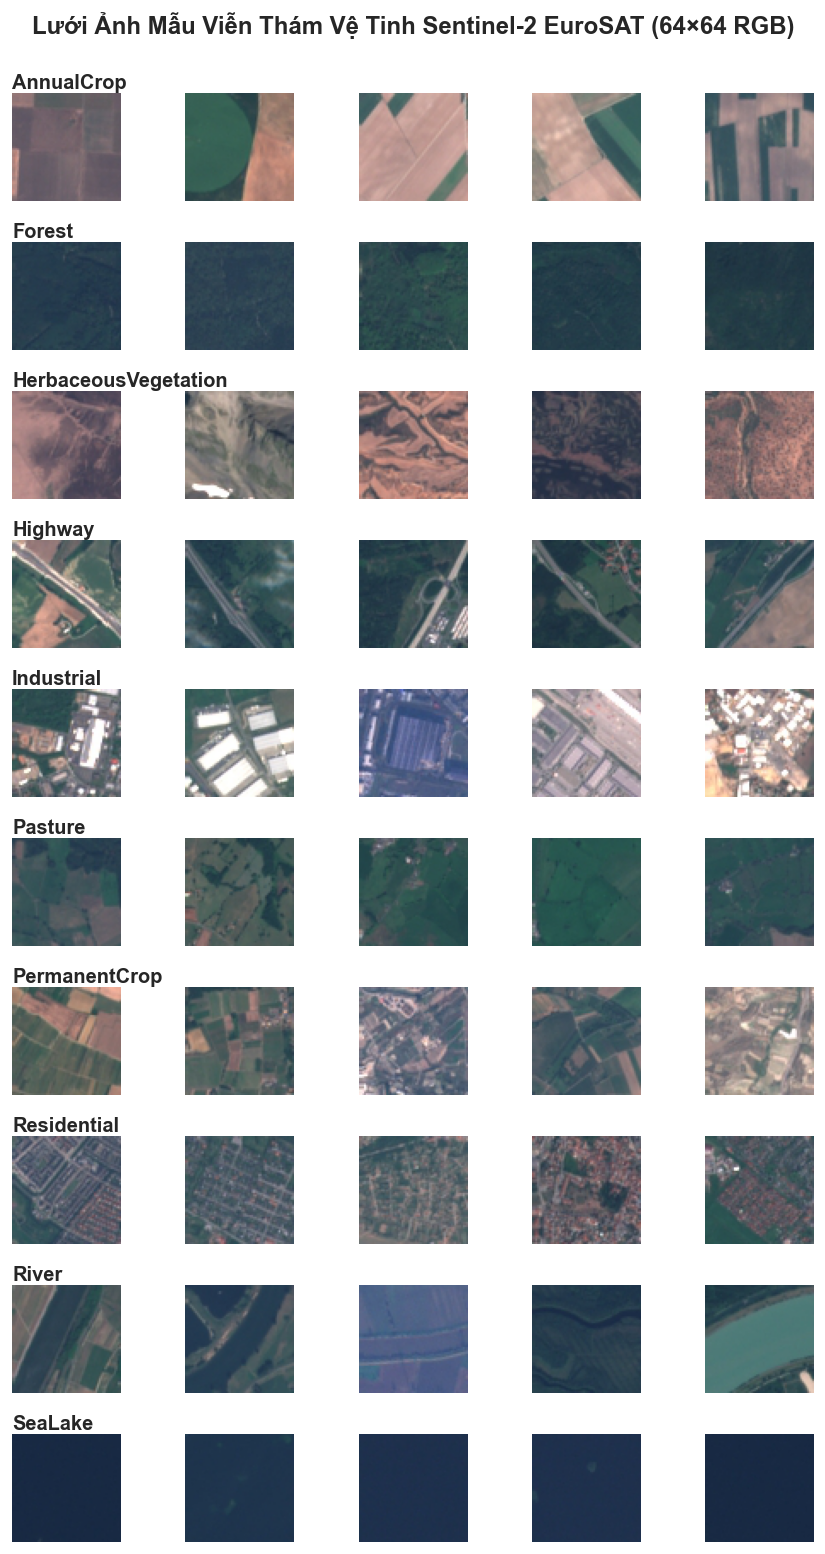

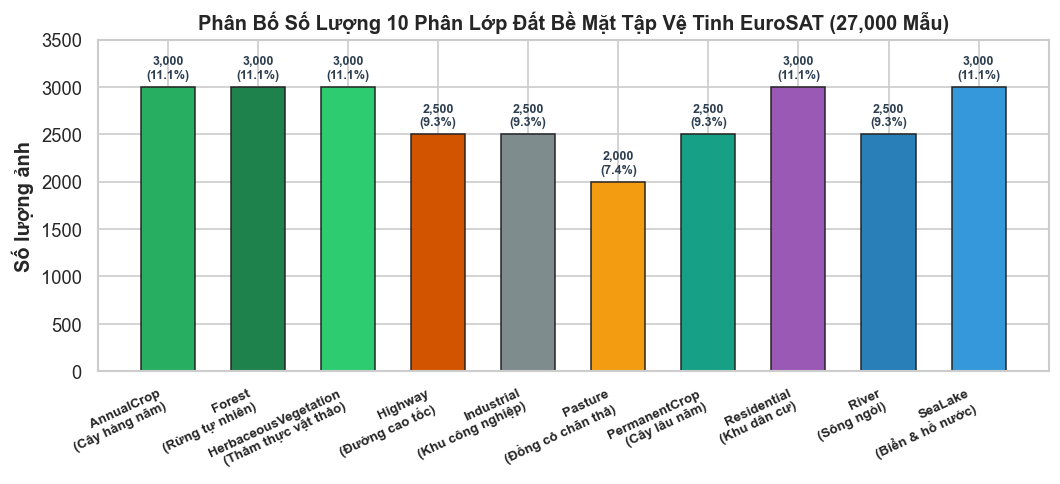

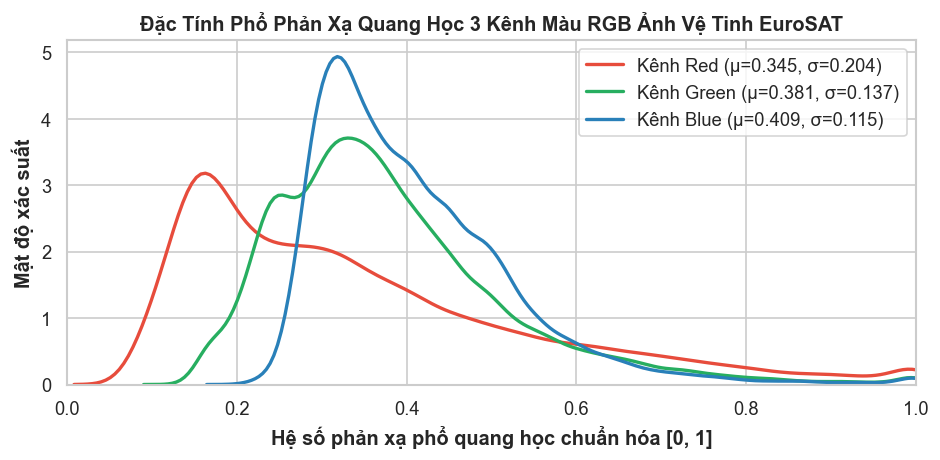

In [10]:
# 1. Lưới ảnh mẫu viễn thám 10 lớp x 5 mẫu
fig, axes = plt.subplots(10, 5, figsize=(7.5, 13.0), dpi=120)
euro_samples = {c: [] for c in range(10)}
for img, lbl in eurosat_raw:
    if len(euro_samples[lbl]) < 5:
        euro_samples[lbl].append(np.array(img))
    if all(len(v) == 5 for v in euro_samples.values()):
        break

for c in range(10):
    c_name = euro_classes[c]
    for col in range(5):
        ax = axes[c, col]
        ax.imshow(euro_samples[c][col])
        ax.axis('off')
        if col == 0:
            ax.set_title(f"{c_name}", fontweight='bold', loc='left', pad=2)

plt.suptitle("Lưới Ảnh Mẫu Viễn Thám Vệ Tinh Sentinel-2 EuroSAT (64×64 RGB)", fontweight='bold', y=0.995)
plt.tight_layout()
plt.show()

# 2. Phân bố số lượng mẫu 10 phân lớp LULC
fig, ax = plt.subplots(figsize=(9.0, 4.2), dpi=120)
x_euro = np.arange(10)
bar_colors = ['#27ae60', '#1e824c', '#2ecc71', '#d35400', '#7f8c8d', '#f39c12', '#16a085', '#9b59b6', '#2980b9', '#3498db']
bars_e = ax.bar(x_euro, counts, color=bar_colors, edgecolor='#222222', lw=0.9, width=0.6)
ax.set_xticks(x_euro)
ax.set_xticklabels([f"{euro_classes[i]}\n({euro_vn_names[euro_classes[i]]})" for i in range(10)], fontsize=8.0, fontweight='bold', rotation=25, ha='right')
ax.set_ylabel("Số lượng ảnh", fontweight='bold')
ax.set_ylim(0, 3500)
ax.set_title("Phân Bố Số Lượng 10 Phân Lớp Đất Bề Mặt Tập Vệ Tinh EuroSAT (27,000 Mẫu)", fontweight='bold')
for bar in bars_e:
    h = bar.get_height()
    pct = h / 27000 * 100
    ax.text(bar.get_x() + bar.get_width()/2, h + 60, f'{h:,}\n({pct:.1f}%)', ha='center', va='bottom', fontsize=7.5, fontweight='bold', color='#2c3e50')
plt.tight_layout()
plt.show()

# 3. Phổ phản xạ quang học 3 kênh RGB
fig, ax = plt.subplots(figsize=(8.0, 4.0), dpi=120)
np.random.seed(42)
sub_euro_idx = np.random.choice(len(eurosat_raw), 2000, replace=False)
e_r, e_g, e_b = [], [], []
for i in sub_euro_idx:
    arr = np.array(eurosat_raw[i][0], dtype=np.float32) / 255.0
    e_r.append(arr[:, :, 0].flatten())
    e_g.append(arr[:, :, 1].flatten())
    e_b.append(arr[:, :, 2].flatten())

e_r = np.concatenate(e_r)
e_g = np.concatenate(e_g)
e_b = np.concatenate(e_b)

r_m, r_s = e_r.mean(), e_r.std()
g_m, g_s = e_g.mean(), e_g.std()
b_m, b_s = e_b.mean(), e_b.std()

sub_pts = np.random.choice(len(e_r), 50000, replace=False)
sns.kdeplot(e_r[sub_pts], ax=ax, color='#e74c3c', label=f'Kênh Red (μ={r_m:.3f}, σ={r_s:.3f})', lw=2.0)
sns.kdeplot(e_g[sub_pts], ax=ax, color='#27ae60', label=f'Kênh Green (μ={g_m:.3f}, σ={g_s:.3f})', lw=2.0)
sns.kdeplot(e_b[sub_pts], ax=ax, color='#2980b9', label=f'Kênh Blue (μ={b_m:.3f}, σ={b_s:.3f})', lw=2.0)
ax.set_xlim(0, 1)
ax.set_xlabel("Hệ số phản xạ phổ quang học chuẩn hóa [0, 1]", fontweight='bold')
ax.set_ylabel("Mật độ xác suất", fontweight='bold')
ax.set_title("Đặc Tính Phổ Phản Xạ Quang Học 3 Kênh Màu RGB Ảnh Vệ Tinh EuroSAT", fontweight='bold')
ax.legend()
plt.tight_layout()
plt.show()


### 3.3. Pipeline Tăng Cường Đối Xứng Đẳng Hướng & Phân Chia Train/Val/Test
Khác với ký tự SVHN có chiều đọc cố định, ảnh vệ tinh chụp từ phương thẳng đứng (nadir observation) sở hữu tính **bất biến quay và đối xứng hoàn toàn 2D**. Do đó:
- Áp dụng cả lật ngang (`RandomHorizontalFlip`) và lật dọc (`RandomVerticalFlip`).
- Áp dụng phép quay tự do góc nhỏ (`RandomRotation(degrees=15)`).
- Phân chia phân tầng chuẩn: Train ($80\% = 21,600$ ảnh) và Test ($20\% = 5,400$ ảnh).


In [11]:
euro_mean = (0.344, 0.380, 0.408)
euro_std = (0.093, 0.065, 0.054)

euro_train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(degrees=15),
    transforms.ToTensor(),
    transforms.Normalize(mean=euro_mean, std=euro_std)
])

euro_test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=euro_mean, std=euro_std)
])

# Phân chia 80% Train, 20% Test
generator = torch.Generator().manual_seed(42)
train_size = int(0.8 * len(eurosat_raw))
test_size = len(eurosat_raw) - train_size
train_indices, test_indices = random_split(range(len(eurosat_raw)), [train_size, test_size], generator=generator)

class SubsetEuroSAT(Dataset):
    def __init__(self, base_ds, indices, transform=None):
        self.base_ds = base_ds
        self.indices = indices
        self.transform = transform
        
    def __len__(self):
        return len(self.indices)
        
    def __getitem__(self, idx):
        img, label = self.base_ds[self.indices[idx]]
        if self.transform is not None:
            img = self.transform(img)
        return img, label

euro_train_ds = SubsetEuroSAT(eurosat_raw, train_indices, transform=euro_train_transform)
euro_test_ds = SubsetEuroSAT(eurosat_raw, test_indices, transform=euro_test_transform)

euro_train_loader = DataLoader(euro_train_ds, batch_size=64, shuffle=True, num_workers=0, pin_memory=True)
euro_test_loader = DataLoader(euro_test_ds, batch_size=64, shuffle=False, num_workers=0, pin_memory=True)

batch_imgs, batch_lbls = next(iter(euro_train_loader))
print(f"EuroSAT Train Batch Images Shape: {batch_imgs.shape} (dtype: {batch_imgs.dtype})")
print(f"EuroSAT Train Batch Labels Shape: {batch_lbls.shape} (dtype: {batch_lbls.dtype})")


EuroSAT Train Batch Images Shape: torch.Size([64, 3, 64, 64]) (dtype: torch.float32)
EuroSAT Train Batch Labels Shape: torch.Size([64]) (dtype: torch.int64)


---
## Phần 4: Tổng Hợp Đối Chuẩn Cấu Trúc 3 Bộ Dữ Liệu & Sẵn Sàng Cho Huấn Luyện


In [12]:
summary_matrix = pd.DataFrame([
    {
        "Tập Dữ Liệu": "Diabetes Prediction (100k)",
        "Miền Dữ Liệu": "Bảng Y Sinh (Tabular)",
        "Kích Thước Đầu Vào": "Tensor (1, 8)",
        "Tổng Mẫu": f"{len(df_clean):,} (sạch)",
        "Số Lớp": "2 lớp (91.2% Âm / 8.8% Dương)",
        "Chuẩn Hóa": "StandardScaler",
        "Data Augmentation": "Không áp dụng",
        "Kiến Trúc Đề Xuất": "1D-CNN (Mạng tích chập 1 chiều)"
    },
    {
        "Tập Dữ Liệu": "SVHN",
        "Miền Dữ Liệu": "Ảnh Ngoại Cảnh Tự Nhiên",
        "Kích Thước Đầu Vào": "Tensor 3x32x32",
        "Tổng Mẫu": f"{len(svhn_raw_train)+len(svhn_raw_test):,}",
        "Số Lớp": "10 chữ số (0-9)",
        "Chuẩn Hóa": f"Mean={svhn_mean}, Std={svhn_std}",
        "Data Augmentation": "RandomCrop, ColorJitter (CẤM lật)",
        "Kiến Trúc Đề Xuất": "Baseline CNN, VGG-11, ResNet-18"
    },
    {
        "Tập Dữ Liệu": "EuroSAT (Sentinel-2)",
        "Miền Dữ Liệu": "Ảnh Viễn Thám Vệ Tinh",
        "Kích Thước Đầu Vào": "Tensor 3x64x64",
        "Tổng Mẫu": f"{len(eurosat_raw):,}",
        "Số Lớp": "10 phân lớp LULC đất bề mặt",
        "Chuẩn Hóa": f"Mean={euro_mean}, Std={euro_std}",
        "Data Augmentation": "Flip H/V, Rotation (Đẳng hướng 2D)",
        "Kiến Trúc Đề Xuất": "ResNet-18, MobileNetV2, Transfer Learning"
    }
])

display(summary_matrix)
print("\n=== HOÀN TẤT EDA & THIẾT LẬP PIPELINE TIỀN XỬ LÝ CHO CẢ 3 BỘ DỮ LIỆU ĐA MIỀN ===")


,Tập Dữ Liệu,Miền Dữ Liệu,Kích Thước Đầu Vào,Tổng Mẫu,Số Lớp,Chuẩn Hóa,Data Augmentation,Kiến Trúc Đề Xuất
0,Diabetes Prediction (100k),Bảng Y Sinh (Tabular),"Tensor (1, 8)","96,128 (sạch)",2 lớp (91.2% Âm / 8.8% Dương),StandardScaler,Không áp dụng,1D-CNN (Mạng tích chập 1 chiều)
1,SVHN,Ảnh Ngoại Cảnh Tự Nhiên,Tensor 3x32x32,"99,289",10 chữ số (0-9),"Mean=(0.435, 0.44, 0.469), Std=(0.192, 0.193, ...","RandomCrop, ColorJitter (CẤM lật)","Baseline CNN, VGG-11, ResNet-18"
2,EuroSAT (Sentinel-2),Ảnh Viễn Thám Vệ Tinh,Tensor 3x64x64,"27,000",10 phân lớp LULC đất bề mặt,"Mean=(0.344, 0.38, 0.408), Std=(0.093, 0.065, ...","Flip H/V, Rotation (Đẳng hướng 2D)","ResNet-18, MobileNetV2, Transfer Learning"



=== HOÀN TẤT EDA & THIẾT LẬP PIPELINE TIỀN XỬ LÝ CHO CẢ 3 BỘ DỮ LIỆU ĐA MIỀN ===
